# Eliminating the convergence confusion

Folder-12's sweep showed **separate** beating **combined** at a 400-epoch budget. The one
surviving objection was *"combined is only behind because it hadn't finished training."*
This notebook analyses the 1000-epoch, single-cell run that settles it:

`adam, lr=0.003, batch=256, init=normal, seed=0, all 7 thresholds, early stopping DISABLED`

Every figure is written to `artifacts/`. All plots read the local `runs/*/metrics_*.json`
(wandb not required). Conventions: **purple = combined (solid), orange = separate (dashed)** --
colour *and* linestyle both carry identity, so the series stay distinguishable in greyscale and
for colour-vision deficiency. Threshold uses a sequential viridis ramp because alpha is ordered.


In [1]:
import glob, json, os
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt

RUNS_DIR      = 'runs'
ARTIFACTS_DIR = 'artifacts'
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

# fixed identity per architecture: colour + linestyle + marker (never colour alone)
STYLE = {'combined': dict(color='#9467bd', ls='-',  marker='P', label='combined'),
         'separate': dict(color='#ff7f0e', ls='--', marker='X', label='separate')}
DIVERGE_CUTOFF = 5.0   # nats; a healthy curve here lives in ~[0,2.2]. Guards against the rare
                       # Adam instability spike seen in folder 12 (7/256 runs, all separate).

R = {}    # R[(arch, thr)] = metrics dict
for mp in sorted(glob.glob(os.path.join(RUNS_DIR, '*', 'metrics_*.json'))):
    m = json.load(open(mp))
    R[(m['arch'], m['threshold'])] = m

THRS  = sorted({t for _, t in R})
ARCHS = ['combined', 'separate']
print(f'{len(R)} runs loaded | thresholds: {THRS}')
if R:
    any_m = next(iter(R.values()))
    c = any_m['config']
    print(f"cell: {c['optimizer']} lr={c['lr']} b={c['batch_size']} init={c['init']} "
          f"epochs={c['epochs']} early_stop={c['early_stop']} seed={c['seed']}")
    print()
    print(f"{'thr':>5s} {'arch':>9s} {'ep':>5s} {'best_train':>11s} {'test@best':>10s} "
          f"{'final_tr':>9s} {'final_te':>9s} {'max_tr':>8s}")
    for t in THRS:
        for a in ARCHS:
            if (a, t) not in R: continue
            m = R[(a, t)]
            mx = max(m['history']['train_loss'])
            flag = '  <-- SPIKE' if mx > DIVERGE_CUTOFF else ''
            print(f"{t:5.1f} {a:>9s} {m['epochs_run']:5d} {m['best_train']:11.4f} "
                  f"{m['test_at_best']:10.4f} {m['final_train']:9.4f} {m['final_test']:9.4f} "
                  f"{mx:8.2f}{flag}")


14 runs loaded | thresholds: [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
cell: adam lr=0.003 b=256 init=normal epochs=1000 early_stop=False seed=0

  thr      arch    ep  best_train  test@best  final_tr  final_te   max_tr
  0.4  combined  1000      1.7738     1.8124    1.7738    1.8124     2.33
  0.4  separate  1000      1.7584     1.7836    1.7587    1.7837     2.40
  0.5  combined  1000      1.7037     1.7395    1.7039    1.7402     2.29
  0.5  separate  1000      1.6953     1.7202    1.6956    1.7203     2.36
  0.6  combined  1000      1.6039     1.6302    1.6039    1.6302     2.26
  0.6  separate  1000      1.5943     1.6143    1.5945    1.6141     2.32
  0.7  combined  1000      1.4638     1.4857    1.4638    1.4861     2.23
  0.7  separate  1000      1.4483     1.4695    1.4484    1.4706     2.28
  0.8  combined  1000      1.2673     1.2877    1.2673    1.2877     2.19
  0.8  separate  1000      1.2571     1.2768    1.2573    1.2763     2.23
  0.9  combined  1000      1.0064     1.0247  

## 1. Cross-entropy vs alpha

The headline comparison. Two panels, one measure each (never two scales on one axis):
test CE at the best-train checkpoint, and test CE at the very last epoch. If the 1000-epoch
budget rescued combined, these curves would meet.


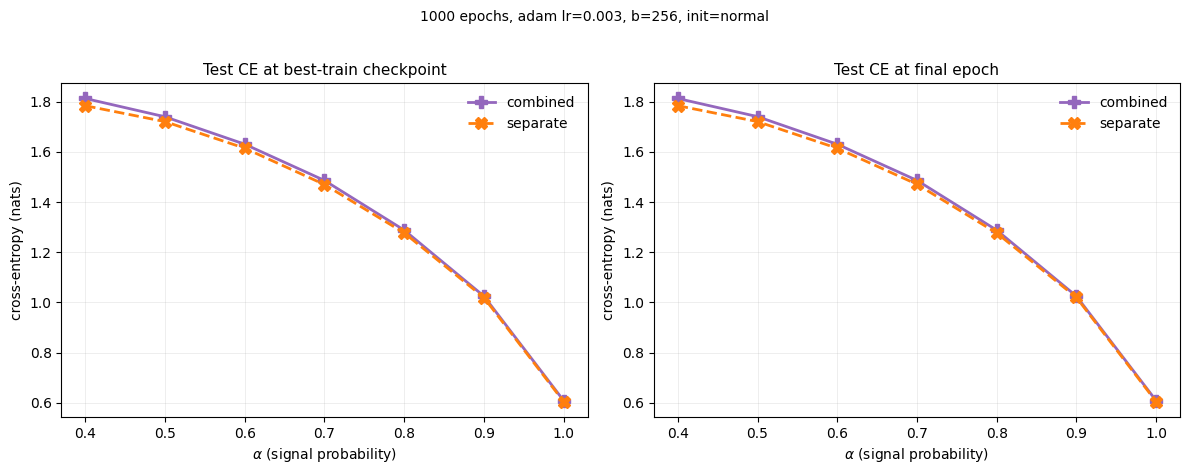

  thr      comb       sep       gap    gap%   (test @ best-train)
  0.4    1.8124    1.7836   +0.0288  +1.62%
  0.5    1.7395    1.7202   +0.0193  +1.12%
  0.6    1.6302    1.6143   +0.0159  +0.98%
  0.7    1.4857    1.4695   +0.0162  +1.10%
  0.8    1.2877    1.2768   +0.0110  +0.86%
  0.9    1.0247    1.0190   +0.0057  +0.56%
  1.0    0.6087    0.6045   +0.0042  +0.70%


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, key, ttl in [(axes[0], 'test_at_best', 'Test CE at best-train checkpoint'),
                     (axes[1], 'final_test',   'Test CE at final epoch')]:
    for a in ARCHS:
        xs = [t for t in THRS if (a, t) in R]
        ys = [R[(a, t)][key] for t in xs]
        s = STYLE[a]
        ax.plot(xs, ys, color=s['color'], ls=s['ls'], marker=s['marker'],
                lw=2, ms=8, label=s['label'])
    ax.set_xlabel(r'$\alpha$ (signal probability)')
    ax.set_ylabel('cross-entropy (nats)')
    ax.set_title(ttl, fontsize=11)
    ax.grid(alpha=0.25, lw=0.6)
    ax.legend(frameon=False)
fig.suptitle('1000 epochs, adam lr=0.003, b=256, init=normal', y=1.02, fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'ce_vs_alpha.png'), dpi=140, bbox_inches='tight')
plt.show()

print(f"{'thr':>5s} {'comb':>9s} {'sep':>9s} {'gap':>9s} {'gap%':>7s}   (test @ best-train)")
for t in THRS:
    if ('combined', t) not in R or ('separate', t) not in R: continue
    c, s = R[('combined', t)]['test_at_best'], R[('separate', t)]['test_at_best']
    print(f'{t:5.1f} {c:9.4f} {s:9.4f} {c - s:+9.4f} {100 * (c - s) / s:+6.2f}%')


## 2. Full training trajectories

One panel per threshold, train and test together, epoch 0 = the random init. This is the raw
evidence for "did it flatten out?". A log x-axis is used so the early transient and the long
tail are both legible in the same panel.


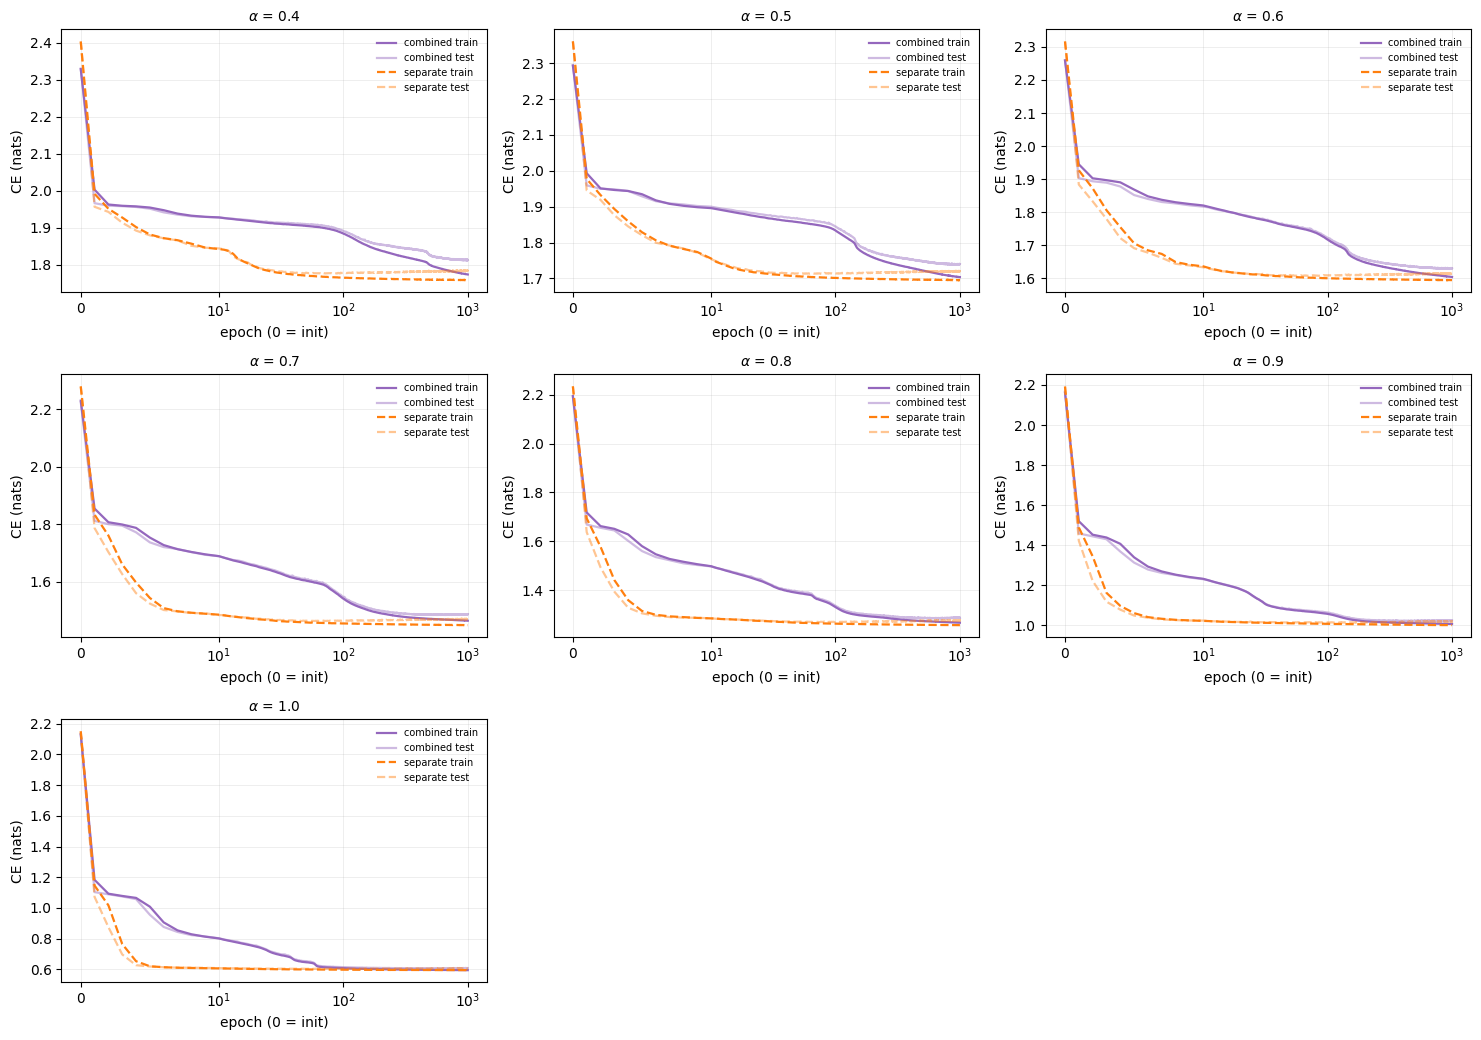

saved 7 per-threshold curve figures -> artifacts/curve_x_<thr>.png


In [3]:
ncols = 3
nrows = int(np.ceil(len(THRS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.0 * ncols, 3.5 * nrows), squeeze=False)
for i, t in enumerate(THRS):
    ax = axes[i // ncols][i % ncols]
    for a in ARCHS:
        if (a, t) not in R: continue
        s = STYLE[a]
        h = R[(a, t)]['history']
        for key, alpha_v, lbl in [('train_loss', 1.0, f"{a} train"),
                                  ('test_loss', 0.45, f"{a} test")]:
            y = np.array(h[key])
            if y.max() > DIVERGE_CUTOFF: continue
            ax.plot(np.arange(len(y)), y, color=s['color'], ls=s['ls'],
                    lw=1.6, alpha=alpha_v, label=lbl)
    ax.set_xscale('symlog', linthresh=10)
    ax.set_title(f'$\\alpha$ = {t}', fontsize=10)
    ax.set_xlabel('epoch (0 = init)'); ax.set_ylabel('CE (nats)')
    ax.grid(alpha=0.25, lw=0.6)
    ax.legend(fontsize=7, frameon=False)
for j in range(len(THRS), nrows * ncols):
    axes[j // ncols][j % ncols].axis('off')
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'curves_grid.png'), dpi=140, bbox_inches='tight')
plt.show()

# also one standalone figure per threshold
for t in THRS:
    fig, ax = plt.subplots(figsize=(7.5, 4.4))
    for a in ARCHS:
        if (a, t) not in R: continue
        s = STYLE[a]; h = R[(a, t)]['history']
        for key, alpha_v in [('train_loss', 1.0), ('test_loss', 0.45)]:
            y = np.array(h[key])
            if y.max() > DIVERGE_CUTOFF: continue
            ax.plot(y, color=s['color'], ls=s['ls'], lw=1.7, alpha=alpha_v,
                    label=f"{a} {key.split('_')[0]}")
    ax.set_title(f'$\\alpha$ = {t}  (1000 epochs)', fontsize=11)
    ax.set_xlabel('epoch (0 = random init)'); ax.set_ylabel('CE (nats)')
    ax.grid(alpha=0.25, lw=0.6); ax.legend(frameon=False, fontsize=9)
    fig.tight_layout()
    fig.savefig(os.path.join(ARTIFACTS_DIR, f'curve_x_{t}.png'), dpi=140)
    plt.close(fig)
print(f'saved {len(THRS)} per-threshold curve figures -> {ARTIFACTS_DIR}/curve_x_<thr>.png')


## 3. Convergence verdict — has combined actually stopped?

The direct test. Minibatch noise makes the raw tail unreadable, so three independent
diagnostics are used together:

- **tail slope** — mean per-epoch change over the last 100 epochs
- **block means** — mean train CE in successive 100-epoch blocks; a converged run has
  equal blocks, a crawling one has monotonically decreasing blocks
- **epoch of minimum** — a run whose global minimum sits in the final few epochs is
  by definition still improving

A run counts as *converged* when the last-100-epoch slope is flatter than `SLOPE_TOL`.


  thr      arch    slope/ep  last100drop  argmin ep    of  verdict
  0.4  combined   -2.59e-05      0.00259       1000  1000  still descending
  0.4  separate   +8.48e-07     -0.00008        994  1000  CONVERGED
  0.5  combined   -2.04e-05      0.00204        997  1000  still descending
  0.5  separate   +6.58e-07     -0.00007        970  1000  CONVERGED
  0.6  combined   -1.84e-05      0.00184       1000  1000  still descending
  0.6  separate   -1.12e-06      0.00011        891  1000  CONVERGED
  0.7  combined   -1.06e-05      0.00106        995  1000  still descending
  0.7  separate   -5.04e-06      0.00050        962  1000  CONVERGED
  0.8  combined   -8.73e-06      0.00087       1000  1000  CONVERGED
  0.8  separate   -1.37e-06      0.00014        951  1000  CONVERGED
  0.9  combined   -7.71e-06      0.00077       1000  1000  CONVERGED
  0.9  separate   +9.46e-07     -0.00009        996  1000  CONVERGED
  1.0  combined   -3.16e-06      0.00032        995  1000  CONVERGED
  1.0  s

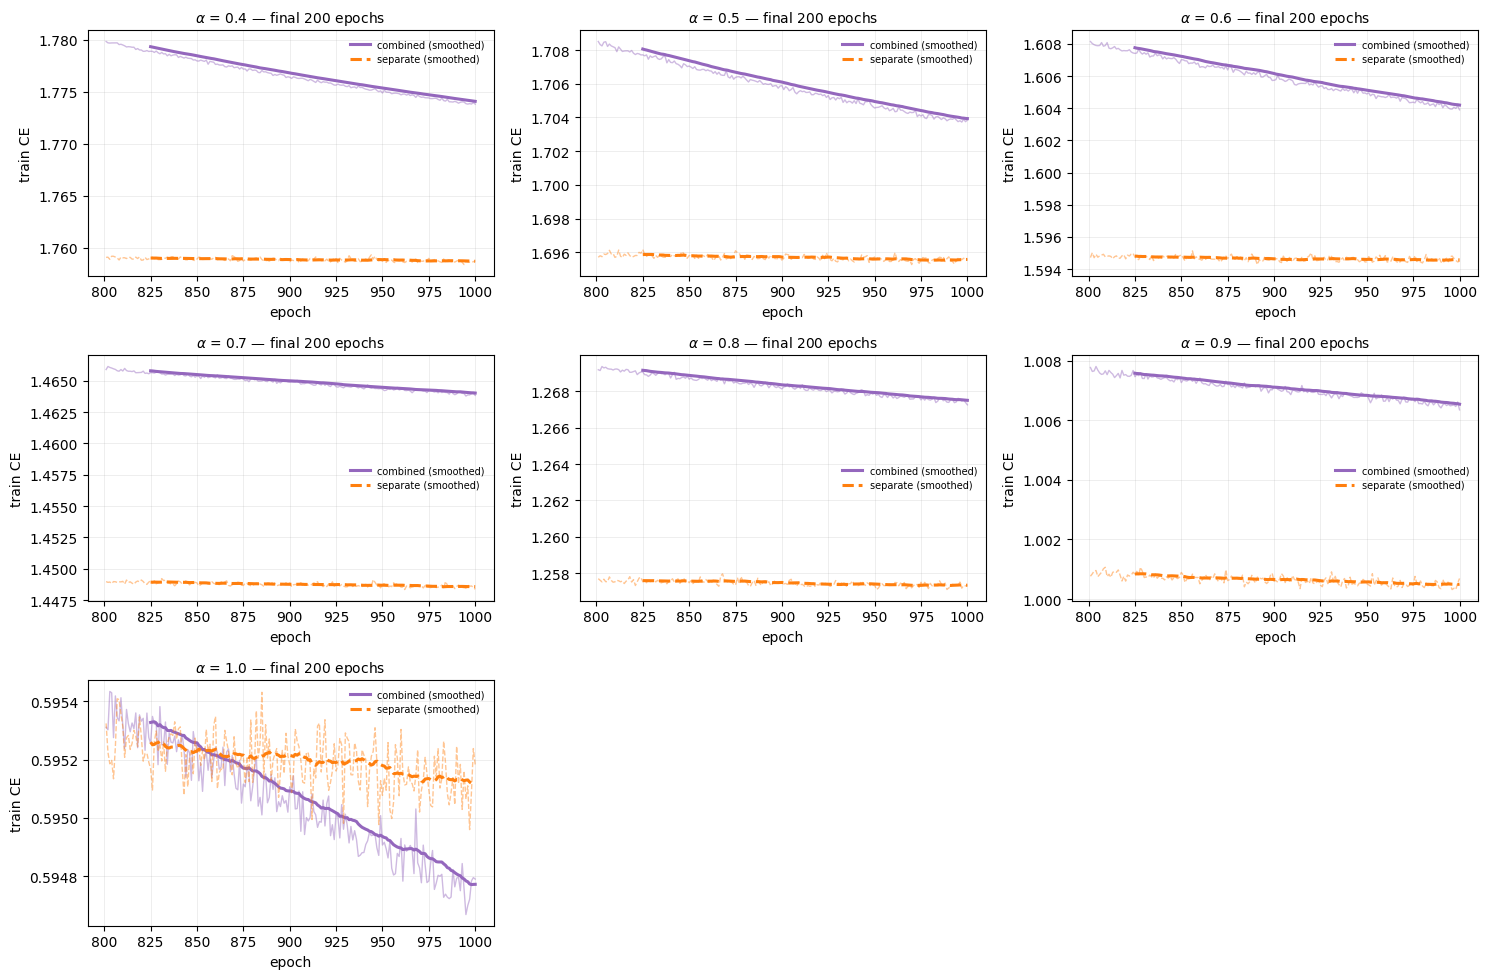

In [4]:
SLOPE_TOL = 1e-5   # nats/epoch; flatter than this counts as converged

def tail_slope(y, w=100):
    w = min(w, len(y) - 1)
    return (y[-1] - y[-1 - w]) / w

rows = []
print(f"{'thr':>5s} {'arch':>9s} {'slope/ep':>11s} {'last100drop':>12s} {'argmin ep':>10s} "
      f"{'of':>5s}  verdict")
for t in THRS:
    for a in ARCHS:
        if (a, t) not in R: continue
        m = R[(a, t)]; y = np.array(m['history']['train_loss'])
        if y.max() > DIVERGE_CUTOFF:
            print(f'{t:5.1f} {a:>9s}   [diverged - excluded]'); continue
        sl = tail_slope(y); drop = y[-101] - y[-1] if len(y) > 101 else np.nan
        amin = int(y.argmin()); n = len(y) - 1
        verdict = 'CONVERGED' if sl > -SLOPE_TOL else 'still descending'
        rows.append(dict(thr=t, arch=a, slope=sl, drop=drop, argmin=amin, n=n,
                         verdict=verdict))
        print(f'{t:5.1f} {a:>9s} {sl:+11.2e} {drop:12.5f} {amin:10d} {n:5d}  {verdict}')

# visualise the tails: last 200 epochs, per threshold, train only
fig, axes = plt.subplots(nrows, ncols, figsize=(5.0 * ncols, 3.3 * nrows), squeeze=False)
for i, t in enumerate(THRS):
    ax = axes[i // ncols][i % ncols]
    for a in ARCHS:
        if (a, t) not in R: continue
        y = np.array(R[(a, t)]['history']['train_loss'])
        if y.max() > DIVERGE_CUTOFF: continue
        s = STYLE[a]; start = max(0, len(y) - 200)
        ax.plot(np.arange(start, len(y)), y[start:], color=s['color'], ls=s['ls'],
                lw=1.0, alpha=0.45)
        # 25-epoch rolling mean makes the trend visible through minibatch noise
        k = 25
        sm = np.convolve(y[start:], np.ones(k) / k, mode='valid')
        ax.plot(np.arange(start + k - 1, len(y)), sm, color=s['color'], ls=s['ls'],
                lw=2.2, label=f'{a} (smoothed)')
    ax.set_title(f'$\\alpha$ = {t} — final 200 epochs', fontsize=10)
    ax.set_xlabel('epoch'); ax.set_ylabel('train CE')
    ax.grid(alpha=0.25, lw=0.6); ax.legend(fontsize=7, frameon=False)
for j in range(len(THRS), nrows * ncols):
    axes[j // ncols][j % ncols].axis('off')
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'convergence_tail.png'), dpi=140, bbox_inches='tight')
plt.show()


In [5]:
# 100-epoch block means: strictly decreasing blocks == still crawling downhill
BLOCK = 100
print('Train-CE block means (100-epoch blocks):')
hdr = f"{'thr':>5s} {'arch':>9s} " + ' '.join(f'{i * BLOCK:>7d}' for i in range(10))
print(hdr)
for t in THRS:
    for a in ARCHS:
        if (a, t) not in R: continue
        y = np.array(R[(a, t)]['history']['train_loss'])
        if y.max() > DIVERGE_CUTOFF: continue
        blocks = [y[i:i + BLOCK].mean() for i in range(0, len(y) - 1, BLOCK)]
        mono = all(b2 < b1 for b1, b2 in zip(blocks[3:], blocks[4:]))
        print(f'{t:5.1f} {a:>9s} ' + ' '.join(f'{b:7.4f}' for b in blocks) +
              ('   [monotone tail]' if mono else ''))


Train-CE block means (100-epoch blocks):
  thr      arch       0     100     200     300     400     500     600     700     800     900
  0.4  combined  1.9127  1.8571  1.8296  1.8175  1.8075  1.7940  1.7871  1.7820  1.7781  1.7751   [monotone tail]
  0.4  separate  1.7939  1.7634  1.7616  1.7606  1.7600  1.7596  1.7594  1.7592  1.7589  1.7588   [monotone tail]
  0.5  combined  1.8687  1.7908  1.7478  1.7344  1.7260  1.7193  1.7140  1.7101  1.7071  1.7047   [monotone tail]
  0.5  separate  1.7284  1.7000  1.6983  1.6974  1.6968  1.6964  1.6962  1.6960  1.6958  1.6956   [monotone tail]
  0.6  combined  1.7736  1.6767  1.6394  1.6279  1.6207  1.6157  1.6121  1.6094  1.6070  1.6049   [monotone tail]
  0.6  separate  1.6262  1.5987  1.5972  1.5964  1.5958  1.5954  1.5951  1.5949  1.5947  1.5946   [monotone tail]
  0.7  combined  1.6234  1.5075  1.4829  1.4750  1.4716  1.4695  1.4678  1.4665  1.4654  1.4644   [monotone tail]
  0.7  separate  1.4808  1.4530  1.4514  1.4506  1.4500  1.4496  

## 4. Does the gap close over training?

If combined were merely slow, the combined−separate gap would shrink toward zero as training
proceeds. Plotting the gap against epoch answers the "would more epochs help?" question
directly — a gap that plateaus at a positive value is the signature of a genuinely worse
solution, not a slower one.


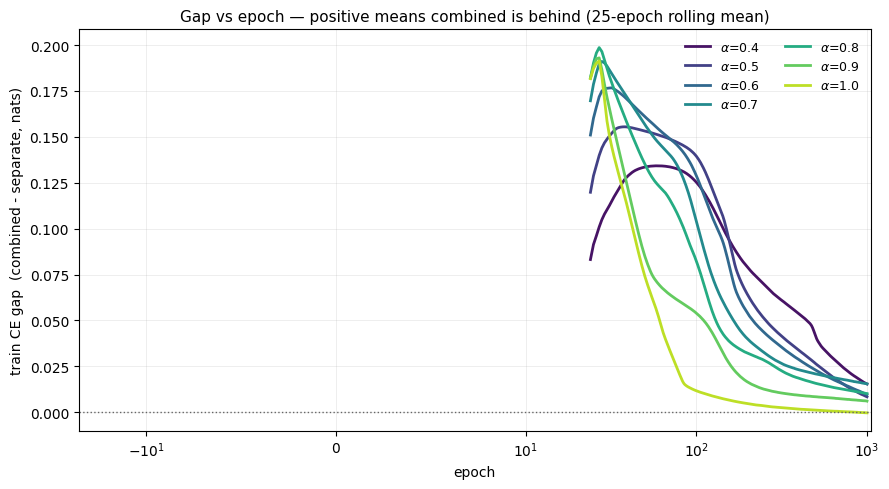

Gap (combined - separate) in train CE, averaged over epoch windows:
  thr  ep100-200  ep400-500  ep900-1000  shrinking?
  0.4     0.0937     0.0475      0.0163         yes
  0.5     0.0908     0.0292      0.0091         yes
  0.6     0.0780     0.0249      0.0103         yes
  0.7     0.0545     0.0216      0.0157         yes
  0.8     0.0407     0.0167      0.0104         yes
  0.9     0.0276     0.0087      0.0062         yes
  1.0     0.0066     0.0013     -0.0003         yes


In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
ramp = plt.cm.viridis(np.linspace(0.05, 0.9, len(THRS)))   # sequential: alpha is ordered
for t, col in zip(THRS, ramp):
    if ('combined', t) not in R or ('separate', t) not in R: continue
    yc = np.array(R[('combined', t)]['history']['train_loss'])
    ys = np.array(R[('separate', t)]['history']['train_loss'])
    if max(yc.max(), ys.max()) > DIVERGE_CUTOFF: continue
    n = min(len(yc), len(ys))
    gap = yc[:n] - ys[:n]
    k = 25
    sm = np.convolve(gap, np.ones(k) / k, mode='valid')
    ax.plot(np.arange(k - 1, n), sm, color=col, lw=2, label=f'$\\alpha$={t}')
ax.axhline(0, color='0.4', lw=1, ls=':')
ax.set_xscale('symlog', linthresh=10)
ax.set_xlabel('epoch'); ax.set_ylabel('train CE gap  (combined - separate, nats)')
ax.set_title('Gap vs epoch — positive means combined is behind (25-epoch rolling mean)',
             fontsize=11)
ax.grid(alpha=0.25, lw=0.6); ax.legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'gap_vs_epoch.png'), dpi=140, bbox_inches='tight')
plt.show()

print('Gap (combined - separate) in train CE, averaged over epoch windows:')
print(f"{'thr':>5s} {'ep100-200':>10s} {'ep400-500':>10s} {'ep900-1000':>11s} {'shrinking?':>11s}")
for t in THRS:
    if ('combined', t) not in R or ('separate', t) not in R: continue
    yc = np.array(R[('combined', t)]['history']['train_loss'])
    ys = np.array(R[('separate', t)]['history']['train_loss'])
    if max(yc.max(), ys.max()) > DIVERGE_CUTOFF: continue
    g = yc - ys
    a1, a2, a3 = g[100:200].mean(), g[400:500].mean(), g[-100:].mean()
    trend = 'yes' if a3 < a2 < a1 else ('flat/widening' if a3 >= a2 else 'mixed')
    print(f'{t:5.1f} {a1:10.4f} {a2:10.4f} {a3:11.4f} {trend:>11s}')


## 5. Convergence speed

How many epochs each architecture needs to reach a loss level *both* demonstrably reach
(the worse of the two `best_train` values). This separates "faster" from "better" — the two
claims the paper makes independently.


  thr   target  comb ep  sep ep  speedup
  0.4   1.7738     1000      39    25.6x
  0.5   1.7037      997      67    14.9x
  0.6   1.6039     1000      54    18.5x
  0.7   1.4638      995      29    34.3x
  0.8   1.2673     1000      49    20.4x
  0.9   1.0064     1000     121     8.3x
  1.0   0.5950      906     997     0.9x


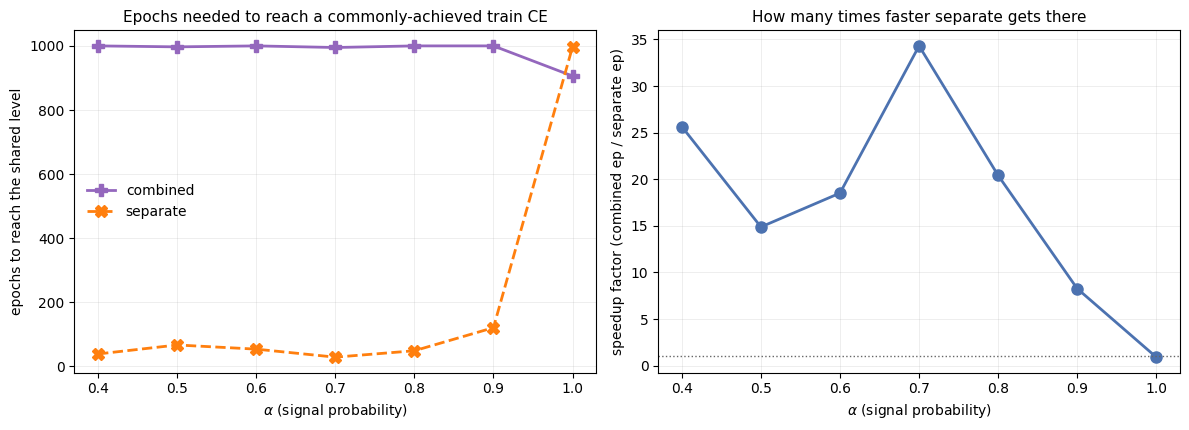

In [7]:
def epochs_to(y, target):
    idx = np.where(np.asarray(y) <= target)[0]
    return int(idx[0]) if len(idx) else None

xs, ratios, ep_c, ep_s = [], [], [], []
print(f"{'thr':>5s} {'target':>8s} {'comb ep':>8s} {'sep ep':>7s} {'speedup':>8s}")
for t in THRS:
    if ('combined', t) not in R or ('separate', t) not in R: continue
    mc, ms = R[('combined', t)], R[('separate', t)]
    yc, ys = np.array(mc['history']['train_loss']), np.array(ms['history']['train_loss'])
    if max(yc.max(), ys.max()) > DIVERGE_CUTOFF: continue
    target = max(mc['best_train'], ms['best_train'])
    ec, es = epochs_to(yc, target), epochs_to(ys, target)
    if ec is None or es is None: continue
    r = ec / max(es, 1)
    xs.append(t); ratios.append(r); ep_c.append(ec); ep_s.append(es)
    print(f'{t:5.1f} {target:8.4f} {ec:8d} {es:7d} {r:7.1f}x')

if xs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    axes[0].plot(xs, ep_c, color=STYLE['combined']['color'], ls='-', marker='P',
                 lw=2, ms=8, label='combined')
    axes[0].plot(xs, ep_s, color=STYLE['separate']['color'], ls='--', marker='X',
                 lw=2, ms=8, label='separate')
    axes[0].set_ylabel('epochs to reach the shared level'); axes[0].legend(frameon=False)
    axes[0].set_title('Epochs needed to reach a commonly-achieved train CE', fontsize=11)
    axes[1].plot(xs, ratios, color='#4c72b0', marker='o', lw=2, ms=8)
    axes[1].axhline(1, color='0.4', lw=1, ls=':')
    axes[1].set_ylabel('speedup factor (combined ep / separate ep)')
    axes[1].set_title('How many times faster separate gets there', fontsize=11)
    for ax in axes:
        ax.set_xlabel(r'$\alpha$ (signal probability)'); ax.grid(alpha=0.25, lw=0.6)
    fig.tight_layout()
    fig.savefig(os.path.join(ARTIFACTS_DIR, 'speed_vs_alpha.png'), dpi=140, bbox_inches='tight')
    plt.show()


## 6. Master summary

Everything in one table, also written to `artifacts/summary.csv` for the write-up.


In [8]:
import csv
out_rows = []
for t in THRS:
    row = {'threshold': t}
    for a in ARCHS:
        if (a, t) not in R: continue
        m = R[(a, t)]; y = np.array(m['history']['train_loss'])
        row[f'{a}_best_train']   = round(m['best_train'], 5)
        row[f'{a}_test_at_best'] = round(m['test_at_best'], 5)
        row[f'{a}_final_test']   = round(m['final_test'], 5)
        row[f'{a}_tail_slope']   = float(f'{tail_slope(y):.3e}')
        row[f'{a}_argmin_ep']    = int(y.argmin())
    if ('combined', t) in R and ('separate', t) in R:
        row['gap_test_at_best'] = round(R[('combined', t)]['test_at_best']
                                        - R[('separate', t)]['test_at_best'], 5)
    out_rows.append(row)

csv_path = os.path.join(ARTIFACTS_DIR, 'summary.csv')
if out_rows:
    with open(csv_path, 'w', newline='') as fh:
        w = csv.DictWriter(fh, fieldnames=list(out_rows[0].keys()))
        w.writeheader(); w.writerows(out_rows)
    print(f'wrote {csv_path}\n')
    keys = list(out_rows[0].keys())
    print(' | '.join(f'{k:>20s}' for k in keys))
    for r in out_rows:
        print(' | '.join(f'{str(r.get(k, "")):>20s}' for k in keys))

print(f'\nAll artifacts in {ARTIFACTS_DIR}/:')
for f in sorted(os.listdir(ARTIFACTS_DIR)):
    print('  ', f)


wrote artifacts/summary.csv

           threshold |  combined_best_train | combined_test_at_best |  combined_final_test |  combined_tail_slope |   combined_argmin_ep |  separate_best_train | separate_test_at_best |  separate_final_test |  separate_tail_slope |   separate_argmin_ep |     gap_test_at_best
                 0.4 |              1.77379 |              1.81242 |              1.81242 |           -2.587e-05 |                 1000 |              1.75838 |              1.78358 |              1.78369 |            8.478e-07 |                  994 |              0.02884
                 0.5 |              1.70373 |              1.73945 |              1.74016 |           -2.043e-05 |                  997 |              1.69527 |              1.72018 |              1.72031 |            6.581e-07 |                  970 |              0.01927
                 0.6 |               1.6039 |              1.63016 |              1.63016 |           -1.836e-05 |                 1000 |          